# 14. UMBRAL POR VARIANZA INTERCLASE — canal Yellow de la imagen plana
Canal Yellow (CMY): **Y = 255 − B**. Se recorre el histograma con un `for` y en cada nivel *i* se separan los píxeles en **fondo** (≤ i) y **objeto** (> i):

- media fondo = suma píxeles fondo / cuántos píxeles fondo
- media objeto = suma píxeles objeto / cuántos píxeles objeto
- **varianza interclase = cuántos píxeles fondo × cuántos píxeles objeto × (media fondo − media objeto)²**

El umbral es el *i* con la varianza interclase más grande. Con ese umbral se sabe cuántos píxeles son fondo y cuántos objeto.

Umbral: 220
Píxeles de fondo:  1069157
Píxeles de objeto: 1291903
Total (ancho*alto): 2361060


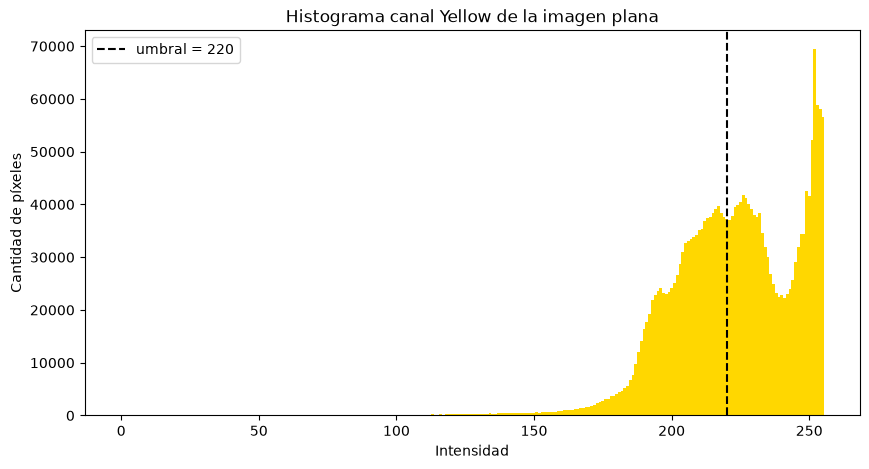

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image 

# Se carga la imagen plana aquí para que la celda funcione aunque se corra sola
foto_rgb = np.array(Image.open(os.path.join("imagenes", "imagen plana", "gatos.JPG")))[:, :, :3]

# Canal Yellow del modelo CMY: Y = 255 - B
amarillo = 255 - foto_rgb[:, :, 2].astype(int)

# Histograma: histograma[i] = cuántos píxeles tienen intensidad i
histograma = [0] * 256
for valor in amarillo.ravel():
    histograma[valor] += 1

area_imagen = amarillo.shape[0] * amarillo.shape[1]          # ancho * alto
suma_todo_histograma = 0
for i in range(256):
    suma_todo_histograma += i * histograma[i]

cuantos_pixeles_fondo = 0
suma_pixeles_fondo = 0
var_pasada = 0
umbral_candidato = 0

for i in range(0, 255):
    cuantos_pixeles_fondo += histograma[i]
    cuantos_pixeles_objeto = area_imagen - cuantos_pixeles_fondo
    suma_pixeles_fondo += i * histograma[i]
    suma_pixeles_objeto = suma_todo_histograma - suma_pixeles_fondo

    if cuantos_pixeles_fondo == 0 or cuantos_pixeles_objeto == 0:   # no se puede dividir por 0
        continue

    mu_fondo = suma_pixeles_fondo / cuantos_pixeles_fondo
    mu_objeto = suma_pixeles_objeto / cuantos_pixeles_objeto
    varianza_interclase = cuantos_pixeles_fondo * cuantos_pixeles_objeto * (mu_fondo - mu_objeto) ** 2

    if varianza_interclase > var_pasada:
        umbral_candidato = i
        var_pasada = varianza_interclase

# cuántos píxeles son fondo y cuántos objeto
pixeles_fondo = 0
for i in range(0, umbral_candidato + 1):
    pixeles_fondo += histograma[i]
pixeles_objeto = area_imagen - pixeles_fondo

print("Umbral:", umbral_candidato)
print("Píxeles de fondo: ", pixeles_fondo)
print("Píxeles de objeto:", pixeles_objeto)
print("Total (ancho*alto):", area_imagen)

plt.figure(figsize=(10, 5))
plt.bar(range(256), histograma, width=1, color="gold")
plt.axvline(umbral_candidato, color="k", ls="--", label=f"umbral = {umbral_candidato}")
plt.title("Histograma canal Yellow de la imagen plana")
plt.xlabel("Intensidad"); plt.ylabel("Cantidad de píxeles"); plt.legend()
plt.show()

# 15. UMBRAL POR VARIANZA INTERCLASE — imagen plana suavizada (Gaussiano 3×3)
La entrada ya no es el canal Yellow: es la **foto plana suavizada con el gaussiano 3×3** de la sección *10.1 Filtros de paso bajo: media y gaussiano* de `ProyectoDicom.ipynb` (`FILTRADAS[("Foto", "Gaussiano 3x3")]`, σ parche = 8,89, 91 % del original). Esa celda la guarda en `imagenes/imagen plana/foto_gaussiano.npy` y aquí solo se **carga** (si no existe, primero hay que ejecutar ProyectoDicom hasta la sección 10.1).

Se trunca a enteros 0–255 para armar el histograma y se aplica el mismo algoritmo de la sección 14: en cada nivel *i* se separan **fondo** (≤ i) y **objeto** (> i), se calcula la **varianza interclase = cuántos fondo × cuántos objeto × (media fondo − media objeto)²** y el umbral es el *i* con la varianza más grande.

Imagen de entrada: foto plana suavizada con Gaussiano 3x3 -> (2018, 1170)
Umbral: 67
Píxeles de fondo:  1495829
Píxeles de objeto: 865231
Total (ancho*alto): 2361060


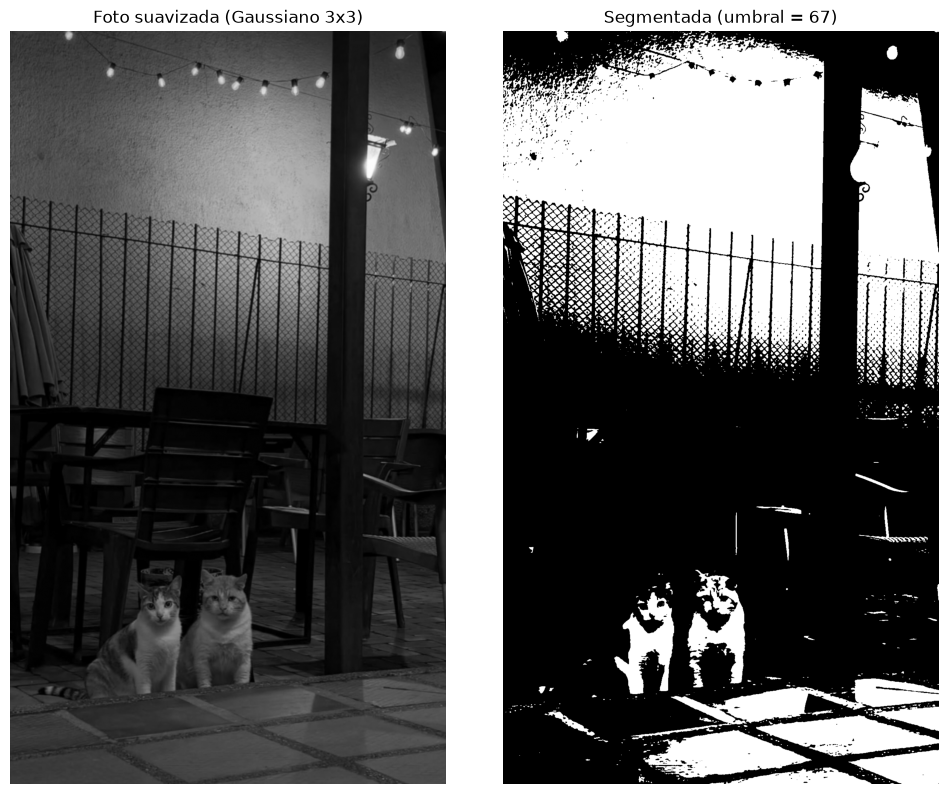

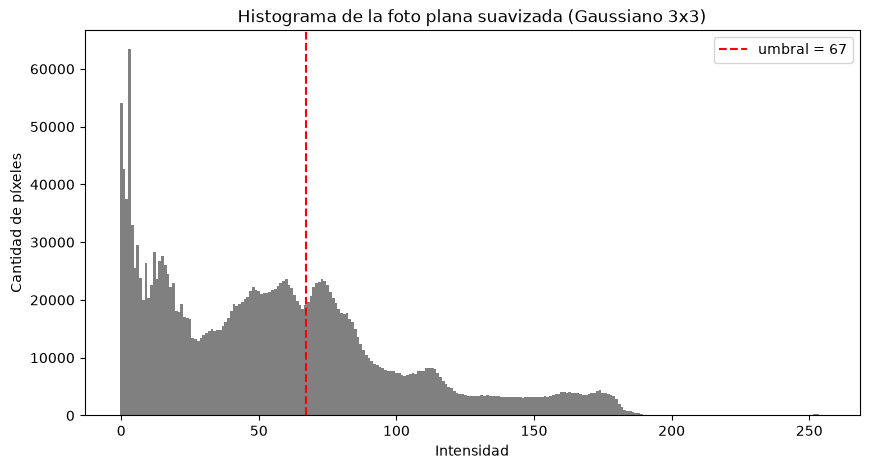

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Imagen ya suavizada en ProyectoDicom.ipynb (sección 10.1, Gaussiano 3x3)
suavizada = np.load(os.path.join("imagenes", "imagen plana", "foto_gaussiano.npy"))

# Imagen de entrada del algoritmo: enteros 0-255
imagen = np.clip(np.floor(suavizada), 0, 255).astype(int)

# Histograma: histograma[i] = cuántos píxeles tienen intensidad i
histograma = [0] * 256
for valor in imagen.ravel():
    histograma[valor] += 1

area_imagen = imagen.shape[0] * imagen.shape[1]          # ancho * alto
suma_todo_histograma = 0
for i in range(256):
    suma_todo_histograma += i * histograma[i]

cuantos_pixeles_fondo = 0
suma_pixeles_fondo = 0
var_pasada = 0
umbral_candidato = 0

for i in range(0, 255):
    cuantos_pixeles_fondo += histograma[i]
    cuantos_pixeles_objeto = area_imagen - cuantos_pixeles_fondo
    suma_pixeles_fondo += i * histograma[i]
    suma_pixeles_objeto = suma_todo_histograma - suma_pixeles_fondo

    if cuantos_pixeles_fondo == 0 or cuantos_pixeles_objeto == 0:   # no se puede dividir por 0
        continue

    mu_fondo = suma_pixeles_fondo / cuantos_pixeles_fondo
    mu_objeto = suma_pixeles_objeto / cuantos_pixeles_objeto
    varianza_interclase = cuantos_pixeles_fondo * cuantos_pixeles_objeto * (mu_fondo - mu_objeto) ** 2

    if varianza_interclase > var_pasada:
        umbral_candidato = i
        var_pasada = varianza_interclase

# cuántos píxeles son fondo y cuántos objeto
pixeles_fondo = 0
for i in range(0, umbral_candidato + 1):
    pixeles_fondo += histograma[i]
pixeles_objeto = area_imagen - pixeles_fondo

print("Imagen de entrada: foto plana suavizada con Gaussiano 3x3 ->", imagen.shape)
print("Umbral:", umbral_candidato)
print("Píxeles de fondo: ", pixeles_fondo)
print("Píxeles de objeto:", pixeles_objeto)
print("Total (ancho*alto):", area_imagen)

# Segmentación: objeto (> umbral) = blanco, fondo (<= umbral) = negro
segmentada = imagen > umbral_candidato

fig, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(imagen, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Foto suavizada (Gaussiano 3x3)"); ax[0].axis("off")
ax[1].imshow(segmentada, cmap="gray"); ax[1].set_title(f"Segmentada (umbral = {umbral_candidato})"); ax[1].axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
plt.bar(range(256), histograma, width=1, color="gray")
plt.axvline(umbral_candidato, color="r", ls="--", label=f"umbral = {umbral_candidato}")
plt.title("Histograma de la foto plana suavizada (Gaussiano 3x3)")
plt.xlabel("Intensidad"); plt.ylabel("Cantidad de píxeles"); plt.legend()
plt.show()

In [3]:
# Erosión 1D con conjuntos: A ⊖ B = { z | (z + B) ⊆ A }
# El origen de B es el centro. Los 1 de B son los vecinos que DEBEN estar en A.
# B = [1 0 1]  →  B_set = {-1, +1}  (izquierda y derecha; el 0 del centro no se exige)

A = [0, 1, 1, 1, 0]
B = [1, 0, 1]

# Conjuntos de posiciones (0-indexadas) donde hay 1
A_set = {i for i, v in enumerate(A) if v == 1}          # {1, 2, 3}
origen = len(B) // 2                                      # centro de B
B_set = {j - origen for j, v in enumerate(B) if v == 1}  # {-1, 1}

print("A_set =", A_set)
print("B_set =", B_set, "  (offsets respecto al origen)")

# Un pixel z sobrevive si TODOS los vecinos exigidos por B están en A
# Hint2: izquierda y derecha en 1  ↔  (z-1) ∈ A y (z+1) ∈ A
erosion_set = {z for z in range(len(A)) if all((z + b) in A_set for b in B_set)}

A_eroded = [1 if i in erosion_set else 0 for i in range(len(A))]

print("A original :", A)
print("A ⊖ B      :", A_eroded)
print("posiciones que sobreviven:", sorted(erosion_set))

# Paso a paso
for z in range(len(A)):
    vecinos = {z + b: ((z + b) in A_set) for b in sorted(B_set)}
    print(f"  z={z}  A[z]={A[z]}  vecinos {vecinos}  →  {'1 (sobrevive)' if z in erosion_set else '0'}")

A_set = {1, 2, 3}
B_set = {1, -1}   (offsets respecto al origen)
A original : [0, 1, 1, 1, 0]
A ⊖ B      : [0, 0, 1, 0, 0]
posiciones que sobreviven: [2]
  z=0  A[z]=0  vecinos {-1: False, 1: True}  →  0
  z=1  A[z]=1  vecinos {0: False, 2: True}  →  0
  z=2  A[z]=1  vecinos {1: True, 3: True}  →  1 (sobrevive)
  z=3  A[z]=1  vecinos {2: True, 4: False}  →  0
  z=4  A[z]=0  vecinos {3: True, 5: False}  →  0
